PRACTICAL 10: VALUE ITERATION IN A GRID WORLD

STEP 1: ENVIRONMENT DEFINITION
---------------------------------------------------------------------------
States: ['A', 'B', 'C', 'G']
Start state: A
Goal state: G
Discount factor: 0.9

Grid:
A -------- B
| |
| |
C -------- G

Available transitions:
A: {'Right': 'B', 'Down': 'C'}
B: {'Left': 'A', 'Down': 'G'}
C: {'Up': 'A', 'Right': 'G'}
G: {}

Rewards for entering states:
R(A) = -1
R(B) = -1
R(C) = -1
R(G) = 10


STEP 2: BELLMAN OPTIMALITY EQUATION
---------------------------------------------------------------------------

For this deterministic environment:

V_new(s) = max over actions a of
           [ R(s') + gamma * V_old(s') ]

where:
    s = current state
    a = selected action
    s' = next state
    R(s') = reward for entering the next state
    gamma = discount factor
    V(s') = estimated future value of the next state

The terminal state's value is fixed at zero because the reward
is received when entering G, and no actions 

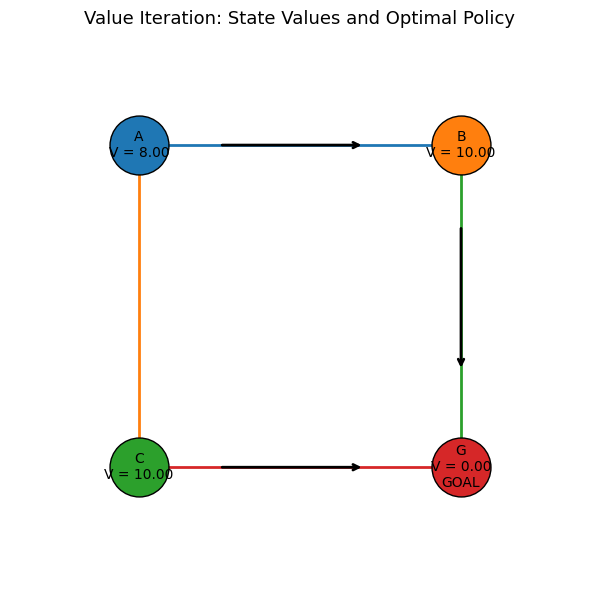



PRACTICAL 10: FINAL SUMMARY
Algorithm: Value Iteration
Environment: Deterministic Grid World
Initial state: A
Goal state: G
Discount factor: 0.9
Converged: True

Final state values:
V(A) = 8.000000
V(B) = 10.000000
V(C) = 10.000000
V(G) = 0.000000

Selected trajectory:
A -> B -> G

Final result:
SUCCESS: Optimal values computed and goal reached.

Key concepts demonstrated:
1. Markov Decision Process
2. Reward and discount factor
3. Bellman optimality equation
4. Value iteration and convergence
5. Optimal policy extraction
6. Policy simulation and validation

PRACTICAL COMPLETED SUCCESSFULLY.


In [ ]:
# =====================================================================
# AI LAB PRACTICAL 10
# VALUE ITERATION IN A SIMPLE GRID WORLD
# B.Tech 5th Semester | Artificial Intelligence Laboratory
# Platform: Google Colab
# =====================================================================
#
# LEARNING OBJECTIVES
# 1. Understand the Markov Decision Process (MDP).
# 2. Define states, actions, transitions, rewards, and discount factor.
# 3. Implement the Bellman optimality equation.
# 4. Perform value iteration until convergence.
# 5. Extract an optimal policy.
# 6. Simulate and validate the selected policy.
#
# REWARD CONVENTION:
# Entering A, B, or C gives reward -1.
# Entering G gives reward +10.
# G is terminal and V(G) remains 0 after arrival.
#
# No installation is required for the core algorithm.
# =====================================================================


# =====================================================================
# STEP 1: IMPORT LIBRARIES
# =====================================================================

import math

print("=" * 75)
print("PRACTICAL 10: VALUE ITERATION IN A GRID WORLD")
print("=" * 75)


# =====================================================================
# STEP 2: DEFINE THE ENVIRONMENT
# =====================================================================

STATES = ["A", "B", "C", "G"]

START_STATE = "A"
GOAL_STATE = "G"
TERMINAL_STATES = {"G"}

NON_TERMINAL_STATES = [
    state for state in STATES
    if state not in TERMINAL_STATES
]

# Grid representation:
#
# A -------- B
# | |
# | |
# C -------- G
#
# Available actions:
# A: Right -> B, Down -> C
# B: Left -> A, Down -> G
# C: Up -> A, Right -> G
# G: Terminal state


TRANSITIONS = {
    "A": {
        "Right": "B",
        "Down": "C"
    },

    "B": {
        "Left": "A",
        "Down": "G"
    },

    "C": {
        "Up": "A",
        "Right": "G"
    },

    "G": {}
}


# =====================================================================
# STEP 3: DEFINE THE REWARD FUNCTION
# =====================================================================

REWARDS = {
    "A": -1,
    "B": -1,
    "C": -1,
    "G": 10
}

GAMMA = 0.9

# Convergence threshold
THETA = 1e-10

# Safety limit for iterations
MAX_ITERATIONS = 1000


print("\nSTEP 1: ENVIRONMENT DEFINITION")
print("-" * 75)

print("States:", STATES)
print("Start state:", START_STATE)
print("Goal state:", GOAL_STATE)
print("Discount factor:", GAMMA)

print("\nGrid:")
print("A -------- B")
print("| |")
print("| |")
print("C -------- G")

print("\nAvailable transitions:")

for state, actions in TRANSITIONS.items():
    print(f"{state}: {actions}")

print("\nRewards for entering states:")

for state, reward in REWARDS.items():
    print(f"R({state}) = {reward}")


# =====================================================================
# STEP 4: EXPLAIN THE BELLMAN OPTIMALITY EQUATION
# =====================================================================

print("\n\nSTEP 2: BELLMAN OPTIMALITY EQUATION")
print("-" * 75)

print("""
For this deterministic environment:

V_new(s) = max over actions a of
           [ R(s') + gamma * V_old(s') ]

where:
    s = current state
    a = selected action
    s' = next state
    R(s') = reward for entering the next state
    gamma = discount factor
    V(s') = estimated future value of the next state

The terminal state's value is fixed at zero because the reward
is received when entering G, and no actions follow termination.
""")


# =====================================================================
# STEP 5: DEFINE THE ACTION-VALUE FUNCTION
# =====================================================================

def calculate_action_value(state, action, values):
    """
    Calculate the one-step value of an action.

    Q(s, a) = R(s') + gamma * V(s')

    The reward is associated with the destination state.
    """

    if state in TERMINAL_STATES:
        raise ValueError(
            f"Cannot select an action from terminal state {state}."
        )

    if action not in TRANSITIONS[state]:
        raise ValueError(
            f"Invalid action {action!r} for state {state!r}."
        )

    next_state = TRANSITIONS[state][action]

    immediate_reward = REWARDS[next_state]

    # Terminal state has no future actions.
    if next_state in TERMINAL_STATES:
        future_value = 0.0
    else:
        future_value = values[next_state]

    action_value = (
        immediate_reward
        + GAMMA * future_value
    )

    return action_value


# =====================================================================
# STEP 6: INITIALIZE STATE VALUES
# =====================================================================

values = {
    state: 0.0
    for state in STATES
}

# Terminal value is fixed at zero under this reward convention.
values[GOAL_STATE] = 0.0

# Store values from every iteration for later inspection.
value_history = [values.copy()]

print("\n\nSTEP 3: INITIALIZATION")
print("-" * 75)

for state in STATES:
    print(f"V0({state}) = {values[state]:.4f}")


# =====================================================================
# STEP 7: IMPLEMENT VALUE ITERATION
# =====================================================================
#
# Important:
# We use synchronous updates.
# Every new value is calculated from the previous value table.
#
# Bellman update:
# V_(k+1)(s) = max_a [ R(s') + gamma * V_k(s') ]
#
# Stop when the largest absolute change is less than THETA.
# =====================================================================

print("\n\nSTEP 4: RUNNING VALUE ITERATION")
print("=" * 75)

print(
    f"{'Iteration':>10} | "
    f"{'V(A)':>12} | "
    f"{'V(B)':>12} | "
    f"{'V(C)':>12} | "
    f"{'Delta':>12}"
)

print("-" * 75)

print(
    f"{0:>10} | "
    f"{values['A']:>12.6f} | "
    f"{values['B']:>12.6f} | "
    f"{values['C']:>12.6f} | "
    f"{'-':>12}"
)

converged = False

for iteration in range(1, MAX_ITERATIONS + 1):

    # Start with a copy of the old values.
    new_values = values.copy()

    # Update all non-terminal states.
    for state in NON_TERMINAL_STATES:

        candidate_values = []

        # Evaluate every legal action.
        for action in TRANSITIONS[state]:

            q_value = calculate_action_value(
                state,
                action,
                values
            )

            candidate_values.append(q_value)

        # Bellman optimality update.
        new_values[state] = max(candidate_values)

    # Keep terminal state fixed at zero.
    new_values[GOAL_STATE] = 0.0

    # Measure the largest value change in this iteration.
    delta = max(
        abs(new_values[state] - values[state])
        for state in STATES
    )

    # Replace the old value table after the full sweep.
    values = new_values.copy()

    value_history.append(values.copy())

    print(
        f"{iteration:>10} | "
        f"{values['A']:>12.6f} | "
        f"{values['B']:>12.6f} | "
        f"{values['C']:>12.6f} | "
        f"{delta:>12.6g}"
    )

    # Convergence condition.
    if delta < THETA:
        converged = True
        break


print("-" * 75)

print("\nConvergence status:", converged)
print("Number of iterations:", len(value_history) - 1)

if not converged:
    print(
        "Warning: maximum iteration limit reached "
        "before meeting the tolerance."
    )


# =====================================================================
# STEP 8: DISPLAY FINAL STATE VALUES
# =====================================================================

print("\n\nSTEP 5: FINAL STATE VALUES")
print("=" * 75)

for state in STATES:
    print(
        f"State {state}: "
        f"V({state}) = {values[state]:.6f}"
    )


# =====================================================================
# STEP 9: EXTRACT THE OPTIMAL POLICY
# =====================================================================
#
# The policy selects the action with the highest action value.
# If two actions have equal values, both are retained.
# =====================================================================

def extract_optimal_policy(values, tie_tolerance=1e-9):
    """
    Return all optimal actions for each non-terminal state.
    """

    policy = {}

    for state in NON_TERMINAL_STATES:

        action_values = {}

        for action in TRANSITIONS[state]:

            action_values[action] = calculate_action_value(
                state,
                action,
                values
            )

        best_value = max(action_values.values())

        best_actions = [
            action
            for action, q_value in action_values.items()
            if abs(q_value - best_value) <= tie_tolerance
        ]

        policy[state] = {
            "best_actions": best_actions,
            "action_values": action_values,
            "best_value": best_value
        }

    return policy


policy = extract_optimal_policy(values)


print("\n\nSTEP 6: OPTIMAL POLICY")
print("=" * 75)

for state, information in policy.items():

    print(f"\nState: {state}")

    print(
        "Optimal action(s):",
        information["best_actions"]
    )

    print(
        "Action values:",
        {
            action: round(value, 6)
            for action, value
            in information["action_values"].items()
        }
    )


# =====================================================================
# STEP 10: SIMULATE THE OPTIMAL POLICY
# =====================================================================

def simulate_policy(
    start_state,
    policy,
    max_steps=20,
    tie_order=None
):
    """
    Simulate the selected policy from a start state.

    If multiple actions are optimal, tie_order chooses which
    equally optimal action to execute first.
    """

    if tie_order is None:
        tie_order = ["Right", "Down", "Left", "Up"]

    if start_state not in STATES:
        raise ValueError("Start state is not part of the environment.")

    current_state = start_state

    trajectory = [current_state]
    actions_taken = []
    cumulative_discounted_return = 0.0

    for step in range(max_steps):

        if current_state in TERMINAL_STATES:
            break

        best_actions = policy[current_state]["best_actions"]

        selected_action = next(
            (
                action
                for action in tie_order
                if action in best_actions
            ),
            best_actions[0]
        )

        next_state = TRANSITIONS[current_state][selected_action]

        reward = REWARDS[next_state]

        cumulative_discounted_return += (
            (GAMMA ** step) * reward
        )

        actions_taken.append(selected_action)
        trajectory.append(next_state)

        print(
            f"Step {step + 1}: "
            f"{current_state} --{selected_action}--> {next_state} "
            f"| Reward = {reward}"
        )

        current_state = next_state

    reached_goal = current_state == GOAL_STATE

    return {
        "trajectory": trajectory,
        "actions": actions_taken,
        "final_state": current_state,
        "reached_goal": reached_goal,
        "discounted_return": cumulative_discounted_return
    }


print("\n\nSTEP 7: POLICY SIMULATION")
print("=" * 75)

simulation = simulate_policy(
    start_state=START_STATE,
    policy=policy
)

print("\nState trajectory:")
print(" -> ".join(simulation["trajectory"]))

print("\nActions taken:")
print(simulation["actions"])

print("\nFinal state:", simulation["final_state"])

print("Goal reached:", simulation["reached_goal"])

print(
    "Discounted return along the selected trajectory:",
    round(simulation["discounted_return"], 6)
)


# =====================================================================
# STEP 11: AUTOMATED VALIDATION
# =====================================================================

print("\n\nSTEP 8: AUTOMATED VALIDATION")
print("=" * 75)

# Validate state definitions.
assert set(STATES) == set(TRANSITIONS.keys()), (
    "Mismatch between states and transition model."
)

assert set(STATES) == set(REWARDS.keys()), (
    "Mismatch between states and reward model."
)

# Validate terminal-state handling.
assert TRANSITIONS[GOAL_STATE] == {}, (
    "The goal state should have no outgoing actions."
)

assert values[GOAL_STATE] == 0.0, (
    "Terminal state value must remain zero."
)

# Validate the optimal values for this specific grid.
assert math.isclose(values["A"], 8.0, abs_tol=1e-6)
assert math.isclose(values["B"], 10.0, abs_tol=1e-6)
assert math.isclose(values["C"], 10.0, abs_tol=1e-6)

# Validate the optimal actions.
assert set(policy["A"]["best_actions"]) == {"Right", "Down"}

assert policy["B"]["best_actions"] == ["Down"]

assert policy["C"]["best_actions"] == ["Right"]

# Validate policy simulation.
assert simulation["reached_goal"], (
    "The selected policy did not reach the goal."
)

assert simulation["final_state"] == GOAL_STATE

print("State definitions: PASSED")
print("Transition model: PASSED")
print("Reward model: PASSED")
print("Terminal-state handling: PASSED")
print("Expected value checks: PASSED")
print("Optimal policy checks: PASSED")
print("Goal-reachability check: PASSED")

print("\nALL VALIDATION CHECKS PASSED.")


# =====================================================================
# STEP 12: OPTIONAL VISUALIZATION
# =====================================================================
# Matplotlib is normally available in Google Colab.
# The algorithm above works even if plotting is unavailable.
# =====================================================================

print("\n\nSTEP 9: VISUALIZATION")

try:

    import matplotlib.pyplot as plt

    positions = {
        "A": (0, 1),
        "B": (1, 1),
        "C": (0, 0),
        "G": (1, 0)
    }

    fig, ax = plt.subplots(figsize=(8, 6))

    # Draw connections between neighboring states.
    connections = [
        ("A", "B"),
        ("A", "C"),
        ("B", "G"),
        ("C", "G")
    ]

    for start, end in connections:

        x1, y1 = positions[start]
        x2, y2 = positions[end]

        ax.plot(
            [x1, x2],
            [y1, y2],
            linewidth=2,
            zorder=1
        )

    # Draw states and display their values.
    for state, (x, y) in positions.items():

        ax.scatter(
            x,
            y,
            s=1800,
            edgecolors="black",
            zorder=3
        )

        label = f"{state}\nV = {values[state]:.2f}"

        if state == GOAL_STATE:
            label += "\nGOAL"

        ax.text(
            x,
            y,
            label,
            ha="center",
            va="center",
            fontsize=10,
            zorder=4
        )

    # Draw one optimal action per non-terminal state.
    for state, information in policy.items():

        selected_action = information["best_actions"][0]

        next_state = TRANSITIONS[state][selected_action]

        x1, y1 = positions[state]
        x2, y2 = positions[next_state]

        ax.annotate(
            "",
            xy=(
                x1 + 0.70 * (x2 - x1),
                y1 + 0.70 * (y2 - y1)
            ),
            xytext=(
                x1 + 0.25 * (x2 - x1),
                y1 + 0.25 * (y2 - y1)
            ),
            arrowprops={
                "arrowstyle": "->",
                "linewidth": 2
            }
        )

    ax.set_title(
        "Value Iteration: State Values and Optimal Policy",
        fontsize=13
    )

    ax.set_xlim(-0.4, 1.4)
    ax.set_ylim(-0.35, 1.35)
    ax.set_aspect("equal")
    ax.axis("off")

    plt.tight_layout()
    plt.show()

except ImportError:

    print(
        "Matplotlib is not available. "
        "The core practical has already completed."
    )


# =====================================================================
# STEP 13: FINAL SUMMARY FOR STUDENTS
# =====================================================================

print("\n\n" + "=" * 75)
print("PRACTICAL 10: FINAL SUMMARY")
print("=" * 75)

print("Algorithm: Value Iteration")
print("Environment: Deterministic Grid World")
print("Initial state:", START_STATE)
print("Goal state:", GOAL_STATE)
print("Discount factor:", GAMMA)
print("Converged:", converged)

print("\nFinal state values:")

for state in STATES:
    print(f"V({state}) = {values[state]:.6f}")

print("\nSelected trajectory:")
print(" -> ".join(simulation["trajectory"]))

print("\nFinal result:")

if converged and simulation["reached_goal"]:
    print("SUCCESS: Optimal values computed and goal reached.")
else:
    print("REVIEW: Check convergence and policy simulation.")

print("\nKey concepts demonstrated:")
print("1. Markov Decision Process")
print("2. Reward and discount factor")
print("3. Bellman optimality equation")
print("4. Value iteration and convergence")
print("5. Optimal policy extraction")
print("6. Policy simulation and validation")

print("\nPRACTICAL COMPLETED SUCCESSFULLY.")
print("=" * 75)


# =====================================================================
# STUDENT EXPERIMENTS
# =====================================================================
#
# Experiment 1:
# Change GAMMA to 0.5 and rerun the entire cell.
#
# Experiment 2:
# Change the reward for entering B:
# REWARDS["B"] = -5
# Observe how the preferred action at A changes.
#
# Experiment 3:
# Add a new state and a longer route to G.
#
# Experiment 4:
# Explain how the Bellman equation changes if a movement has
# multiple possible next states with different probabilities.
#
# Experiment 5:
# Explain the difference between model-based value iteration
# and model-free reinforcement learning.
#
# IMPORTANT:
# Rerun the complete cell after changing the environment.
# =====================================================================